mochammad wildan
202343501453
R6R
prediksi saham buy or sell dengan metode klasifikasi dan decision tree


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/sample_data/global_financial_markets_2000_Now.csv')
print("dataset berhasil dimuat!")

dataset berhasil dimuat!


In [ ]:
#'^GSPC' (S&P 500)
df_saham =df[df['symbol'] == '^GSPC'].copy()

In [ ]:
df_saham['date'] = pd.to_datetime(df_saham['date'])
df_saham = df_saham.sort_values('date')

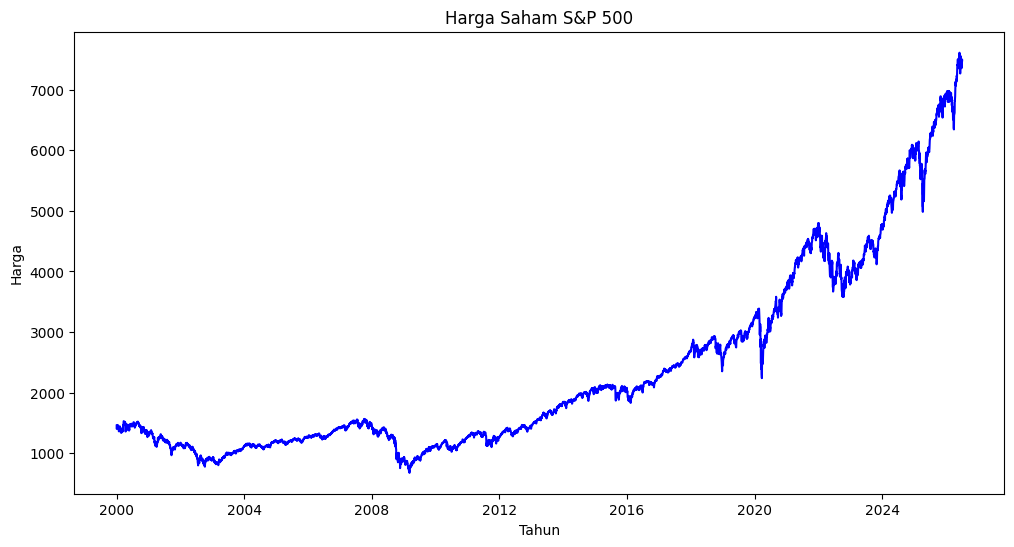

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df_saham['date'], df_saham['close'], color = 'blue')
plt.title('Harga Saham S&P 500')
plt.xlabel('Tahun')
plt.ylabel('Harga')
plt.show()

In [ ]:
df_saham['target'] = (df_saham['close'].shift(-1) > df_saham['close']).astype(int)
df_saham = df_saham.dropna()
print(f"total data siap di gunakan : {len(df_saham)} baris.")

total data siap di gunakan : 6664 baris.


In [ ]:
from sklearn.model_selection import train_test_split

features = ['open', 'high', 'low', 'volume']
X = df_saham[features]
y = df_saham['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
from sklearn.tree import DecisionTreeClassifier


model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test)
print(f"Akurasi model: {accuracy_score(y_test, y_pred)*100:2f}%\n")
print(classification_report(y_test, y_pred))

Akurasi model: 52.813203%

              precision    recall  f1-score   support

           0       0.45      0.14      0.21       609
           1       0.54      0.85      0.66       724

    accuracy                           0.53      1333
   macro avg       0.49      0.50      0.44      1333
weighted avg       0.50      0.53      0.46      1333



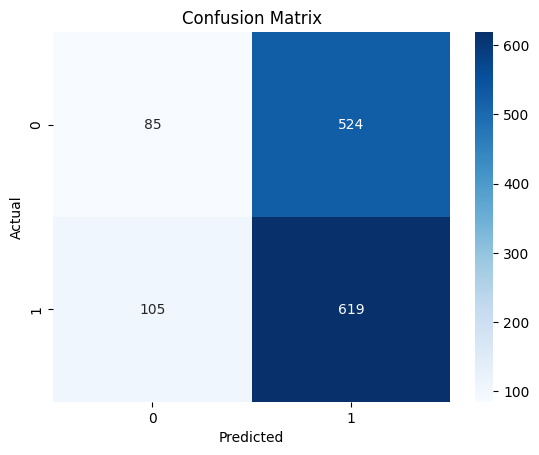

In [ ]:
from sklearn.tree import plot_tree

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


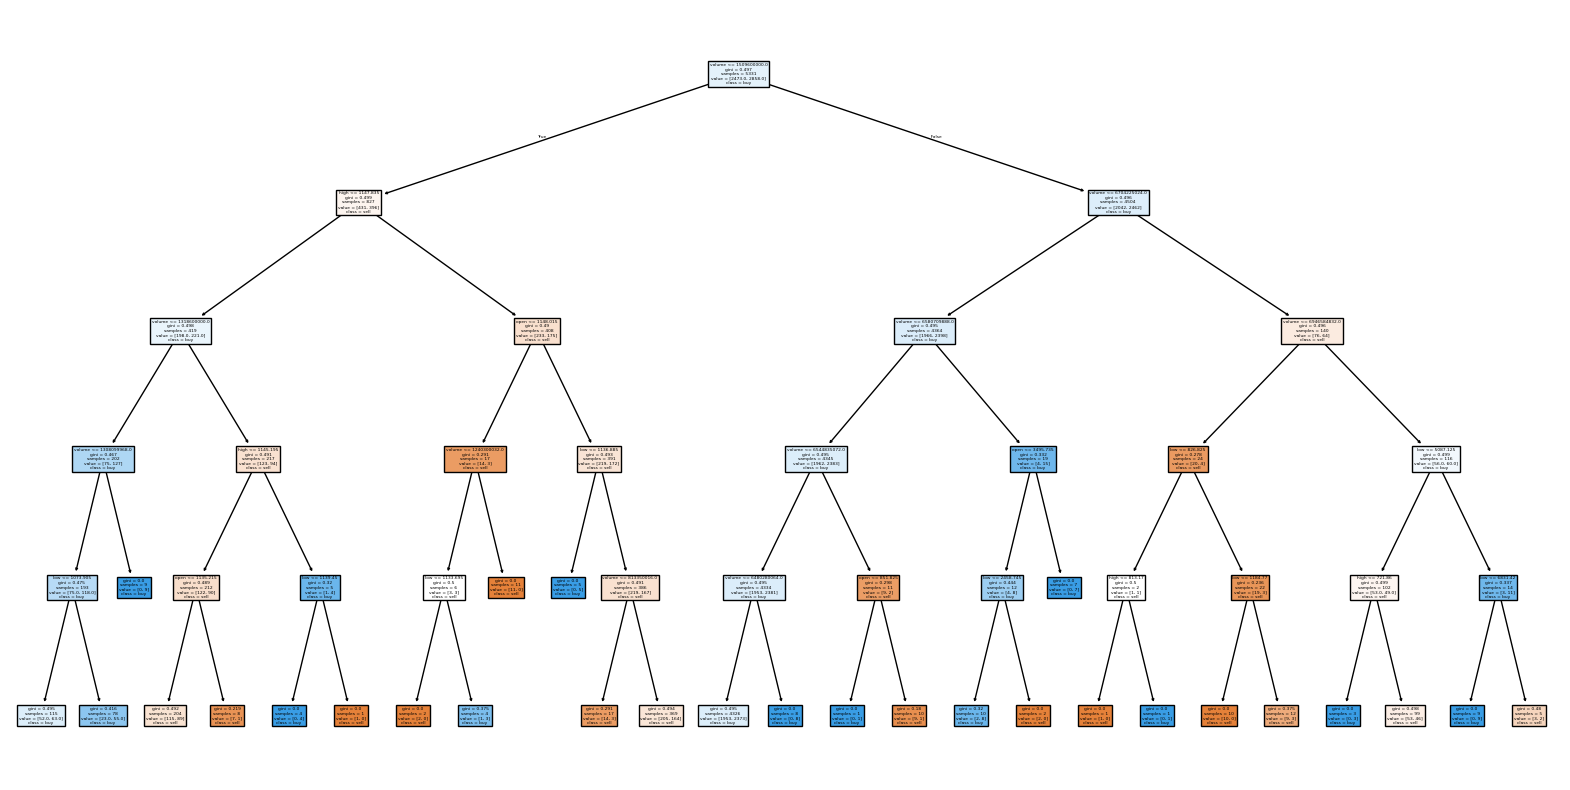

In [ ]:

plt.figure(figsize=(20,10))
plot_tree(model, feature_names=features, class_names=['sell','buy'], filled=True)
plt.show()